# Exercise 1.1
### 1.1.1 Integral evaluation
$$\langle r \rangle = \int_0^1 r \,\mathrm{d}r = \frac{1}{2}$$

> **Goal**: compute $\langle r \rangle$ and its error from a uniform distribution, using a data blocking method..

Generating $\{r_i\}_{i=1}^N$ uniformly on $(0, 1)$, we have 
  - $G_N = \frac{1}{N} \sum_{i=1}^N r_i$ is an estimator for the integral 
  - with variance $\sigma_G^2 = \frac{1}{N} \sum_{i=1}^N r_i^2 - G_N^2$

For $N_{blocks}$ independent blocks each containing $N_{steps}$ samplings and resulting in a succession of $G_{N_{steps}}^{(i)}$ estimates, we have
$$
\langle r \rangle \approx \big\langle G_{N_{steps}}^{(i)} \big\rangle \quad\text{and}\quad \text{err} \approx \sqrt{ \frac{1}{N_{steps} - 1} \bigg[ \big\langle { G_{N_{steps}}^{(i)} }^2 \big\rangle - \big\langle G_{N_{steps}}^{(i)} \big\rangle^2 \bigg] }
$$

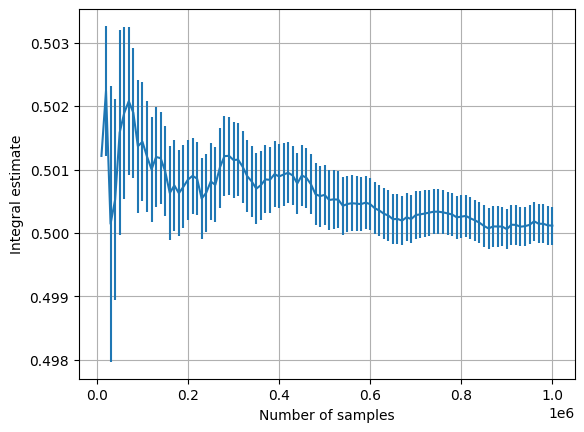

In [ ]:
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import math

def error(av, av2, n):
  # estimates error given the simple average, the average of squares and the number of samples
  if n==1:
    return 0.0
  else:
    return math.sqrt( (av2 - av * av) / (n-1) )

N = int(1e6)  # total number of samples
N_blocks = int(1e2)
N_steps = int(N / N_blocks)

output = subprocess.run(["./run", str(N_steps * N_blocks)], 
                      cwd="./rannyu_rng",
                      capture_output=True,
                      text=True)
data = np.fromstring(output.stdout, sep='\n')

sum_blocks = 0.0
sum2_blocks = 0.0
avg_progr = np.zeros(N_blocks)
err_progr = np.zeros(N_blocks)
for block in range(N_blocks):
  data_block = data[block*N_steps:(block+1)*N_steps:]
  avg = data_block.mean()

  sum_blocks += avg
  sum2_blocks += avg * avg

  avg_current = sum_blocks / (block + 1)
  avg2_current = sum2_blocks / (block + 1)
  err_current = np.sqrt((avg2_current - avg_current * avg_current) / max(block, 1.0))

  avg_progr[block] = avg_current
  err_progr[block] = err_current

plt.errorbar(np.arange(1, N_blocks+1) * N_steps, avg_progr, yerr=err_progr)
plt.xlabel("Number of samples")
plt.ylabel("Integral estimate")
plt.grid(True)

Repeating this computation for different values of $N_{blocks}$ and keeping the total $N$ constant (and the same set of samplings) we get

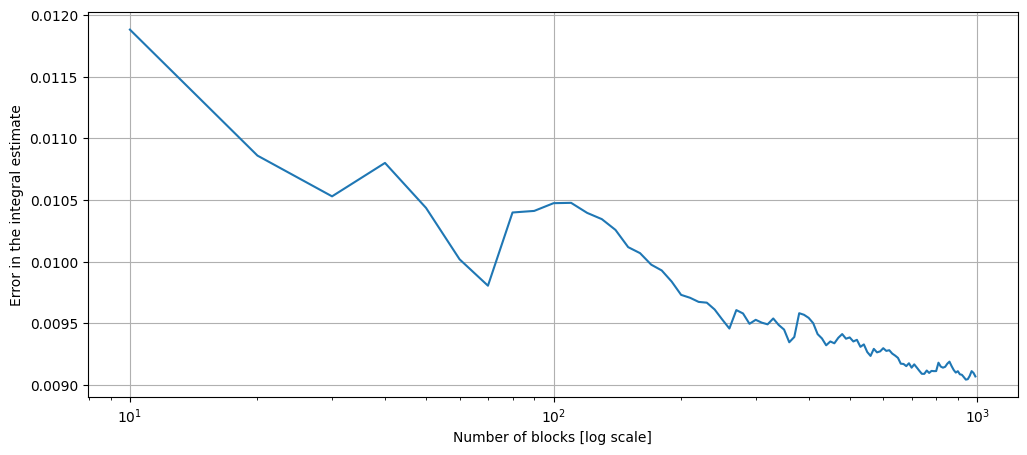

In [21]:
Nblocks_range = np.arange(10, 1000, 10)

def error_est(dataset, Nblocks):
  N = dataset.size
  Nsteps = int(N / N_blocks)

  avg = 0.0
  avg2 = 0.0
  for block in range(Nblocks):
    data_block = dataset[block*Nsteps:(block+1)*Nsteps]
    x = data_block.mean()
    avg += x
    avg2 += x * x
  avg /= Nblocks
  avg2 /= Nblocks

  return np.sqrt((avg2 - avg * avg) / min(Nblocks - 1, 1.0))

errs = np.zeros(Nblocks_range.size)
for i, Nblocks in enumerate(N_blocks_range):
  err = error_est(data, Nblocks)
  errs[i] = err

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(Nblocks_range, errs)
ax.set_xscale("log")
ax.set_xlabel("Number of blocks [log scale]")
ax.set_ylabel("Error in the integral estimate")
ax.grid(True)

This seems to suggest that the error estimate decreases exponentially with the size of blocks.

Naturally this is limited by the total number of steps avaiable and the intrinsic statistical fluctuations of the system.

### 1.1.2 Variance evaluation
$$\sigma^2 = \int_0^1 \big( r - \frac{1}{2} \big)^2 \,\mathrm{d}r = \frac{1}{12}$$

> **Goal**: compute $\sigma^2$ and its error as above

Now the estimate for the integral in each block is
$$
\langle \sigma^2 \rangle_{block} = \langle r^2 \rangle_{block} - \langle r \rangle_{block}^2
$$
and, averaging these across $N_{blocks}$ blocks, the final estimate is
$$
\text{err} = \sqrt{ \frac{1}{N_{blocks} - 1} \bigg[ \big\langle \langle \sigma^2 \rangle_{block}^2 \big\rangle - \big\langle \langle \sigma^2 \rangle_{block} \big\rangle^2 \bigg] }
$$

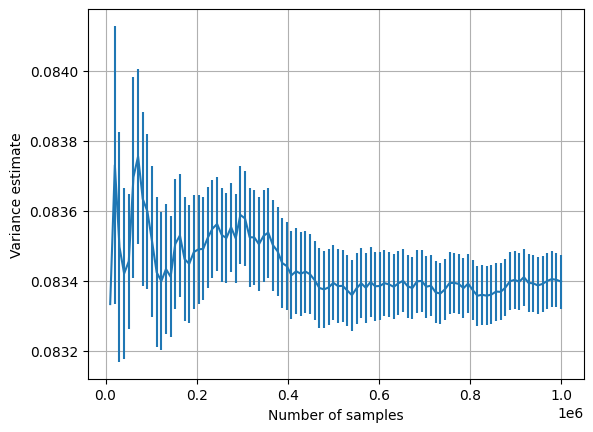

In [ ]:
av_blocks = np.zeros(N_blocks)
av2_blocks = np.zeros(N_blocks)
err_progr = np.zeros(N_blocks)

av = np.zeros(N_blocks)
for block in range(N_blocks):
  sum = 0.0
  sum2 = 0.0
  for step in range(N_steps):
    r = data[step + N_steps * block]
    sum += r
    sum2 += r * r
  av[block] = sum2 / N_steps - (sum / N_steps)**2 # block estimate of variance

  for i in range(N_blocks - block):
    av_blocks[block + i] += av[block] # accumulates progressive sum of block averages
    av2_blocks[block + i] += av[block] * av[block] # accumulates progressive sum of block averages squared

for i in range(N_blocks):
  av_blocks[i] /= i + 1
  av2_blocks[i] /= i + 1
  err_progr[i] = error(av_blocks[i], av2_blocks[i], i+1)

plt.errorbar(np.arange(1, N_blocks+1) * N_steps, av_blocks, yerr=err_progr)
plt.xlabel("Number of samples")
plt.ylabel("Variance estimate")
plt.grid(True)

### 1.1.3 $\chi^2$-test
> **Goal**: test the uniform distribution used previously by computing:
  - $\chi^2$
  - the error on $\chi^2$
> on blocks of samples

In [ ]:
N_bins = 100
bin_width = 1.0 / float(N_bins)
N_samples = int(1e4)
N_blocks = int(N / N_samples)

expect = N_samples / N_bins

chi2 = 0.0
chi2_var = 0.0
err = 0.0
for block in range(N_blocks):
  bins = np.zeros(N_bins)
  for i in range(N_samples):
    r = data[i + N_samples * block]
    n_bin = int(r // bin_width)
    bins[n_bin] += 1

  chi2_block = 0.0
  for value in bins:
    chi2_block += (value - expect)**2
  chi2_block /= expect

  chi2 += chi2_block
  chi2_var += chi2_block * chi2_block

chi2 /= N_blocks
chi2_var /= N_blocks
err = math.sqrt(chi2_var - chi2**2) / (N_blocks - 1)

print(f"Chi^2 = {chi2:.2f} +- {err:.2f}"
      f"\nChi^2 / N_bins = {chi2 / N_bins :.4f} +- {err / N_bins :.4f}")

Chi^2 = 99.76 +- 0.14
Chi^2 / N_bins = 0.9976 +- 0.0014


# Exercise 1.2
> **Goal**: extend the RNG with two additional distributions (exponential and Lorentian) using the method of *inversion of the cumulative distribution*

Random numbers are generated via a `Random` class: this is a rearranged (but functionally identical) version of the one provided:
```cpp
#pragma once

#include <array>
#include <string>
#include <utility>

class Random {
private:
  std::array<int, 4> _seed;
  std::array<int, 4> _n;

public:
  Random(std::string);
  Random();
  void read_seed(std::string);
  void set_seed(const std::array<int, 4>, const std::pair<int, int>);
  void log_last_seed() const;

  double rannyu();
  double rannyu(double, double);
  double gauss(double, double);
};
```

This class has been modified to include its initialization in the constructor and constants used in its methods have been extracted into a namespace.
```cpp
#include "random.hpp"

#include <cmath>
#include <fstream>
#include <iostream>

namespace {
constexpr std::array<int, 4> m = {2107, 4071, 1521, 502};
constexpr double twom12 = 1.0 / 4096.0;
constexpr double pi = 3.141592653589793;
}


/* ******************************* */
/* constructors and initialization */
/* ******************************* */

Random::Random(std::string seed_input_filepath) {
  read_seed(seed_input_filepath);

  std::ifstream primes_stream("input/primes.dat");
  if (!primes_stream) {
    throw std::runtime_error(
        "Unable to open or find \'input/primes.dat\' file.");
  }

  std::pair<int, int> primes;
  primes_stream >> primes.first >> primes.second;

  set_seed(_seed, primes);
}

Random::Random() : Random("input/seed_in.dat") {}

void Random::read_seed(std::string seed_input_filepath) {
  std::ifstream seed_input_stream(seed_input_filepath);
  if (!seed_input_stream) {
    throw std::runtime_error("Unable to open or find \'" + seed_input_filepath +
                             "\' file.");
  }

  std::array<int, 4> seed;
  for (int i = 0; i < 4; i++) {
    seed_input_stream >> seed[3 - i];
  }

  for (auto s : seed) {
    if (s < 0 || s >= 4096) {
      throw std::runtime_error("Seed out of bounds in \'" +
                               seed_input_filepath + "\' file.");
    }
  }

  _seed = seed;
}


/* ************************ */
/* seed reading and writing */
/* ************************ */

void Random::set_seed(const std::array<int, 4> new_seed,
                      const std::pair<int, int> primes) {
  _seed = new_seed;
  _n = {primes.second, primes.first, 0, 0};
}

void Random::log_last_seed() const {
  std::ofstream seed_log_stream("output/last_seed.log");
  if (!seed_log_stream) {
    throw std::runtime_error(
        "Unable to open or generate \'output/last_seed.log\' file.");
  }

  for (int i = 0; i < 4; i++) {
    seed_log_stream << " " << _seed[3 - i];
  }
  seed_log_stream << std::endl;
}
```

The provided number generators have been left mostly the same:
```cpp
double Random::rannyu() {
  const std::array<int, 4> seed_old = _seed;
  std::array<int, 4> tmp{};
  double r = 0.;

  for (int i = 0; i < 4; i++) {
    /* tmp values from seed, m and n */
    tmp[i] = _n[i];
    for (int j = 0; j <= i; j++) {
      tmp[i] += seed_old[i - j] * m[j];
    }

    if (i > 0) {
      tmp[i] += tmp[i - 1] / 4096;
    }

    /* seed values from tmp */
    _seed[i] = tmp[i] % 4096;

    /* build random variable */
    r += _seed[i];
    r = r * twom12;
  }

  return r;
}

double Random::rannyu(double min, double max) {
  return min + (max - min) * rannyu();
}

double Random::gauss(double mean, double sigma) {
  double s = rannyu(), t = rannyu();
  /* normal distribution from 2 uniform numbers in [0,1) */
  double x = std::sqrt(-2. * std::log(1. - s)) * std::cos(2. * pi * t);
  return mean + x * sigma;
}
```

We now add methods for generating
  - a generic decreasing exponential distribution
  - a generic Cauchy-Lorentz distribution 

starting with the uniform distribution $p_{unif}(y) = 1$ in $y \in [0, 1)$ by inverting their respective *cumulative distributions* $F(x)$.

The exponential $p(x) = \lambda \exp(-\lambda x)$ in $x \in [0, +\infty)$ has a cumulative distribution
$$
F(x) = \int_0^x p(x') \mathrm{d}x' = 1 - \exp(- \lambda x)
$$
and can therefore be obtained by sampling
$$
x = F^{-1}(y) = - \frac{1}{\lambda} \ln(1 - y) \quad\text{for } y \in [0, 1) \text{ uniform}
$$

```cpp
double Random::exponential(double lambda) {
  if (lambda <= 0.0) {
    throw std::runtime_error("Error: invalid parameters in sampling a decreasing exponential distribution.");
  }
  return - std::log(1 - rannyu()) / lambda;
}
```

The Cauchy-Lorentz distribution $p(x) = \frac{1}{\pi} \frac{\Gamma}{(x - \mu)^2 + \Gamma^2}$ in $x \in (-\infty, +\infty)$ has a cumulative distribution
$$
F(x) = \int_{-\infty}^x p(x') \,\mathrm{d}x' = \frac{1}{\pi} \tan^{-1}\frac{x - \mu}{\Gamma} + \frac{1}{2}
$$
and can be therefore obtained by sampling
$$
x = F^{-1}(y) = \mu + \Gamma \tan\Big[ \pi\big(y - \frac{1}{2}) \Big]  \quad\text{for } y \in [0, 1) \text{ uniform}
$$

```cpp
double Random::cauchy_lorentz(double mean, double gamma) {
  if (gamma <= 0.0) {
    throw std::runtime_error("Error: invalid parameters in sampling a Cauchy-Lorentz distribution.");
  }
  return mean + gamma * std::tan(pi * ( rannyu() - 0.5 ));
}
```

Then we can sample these distributions running 

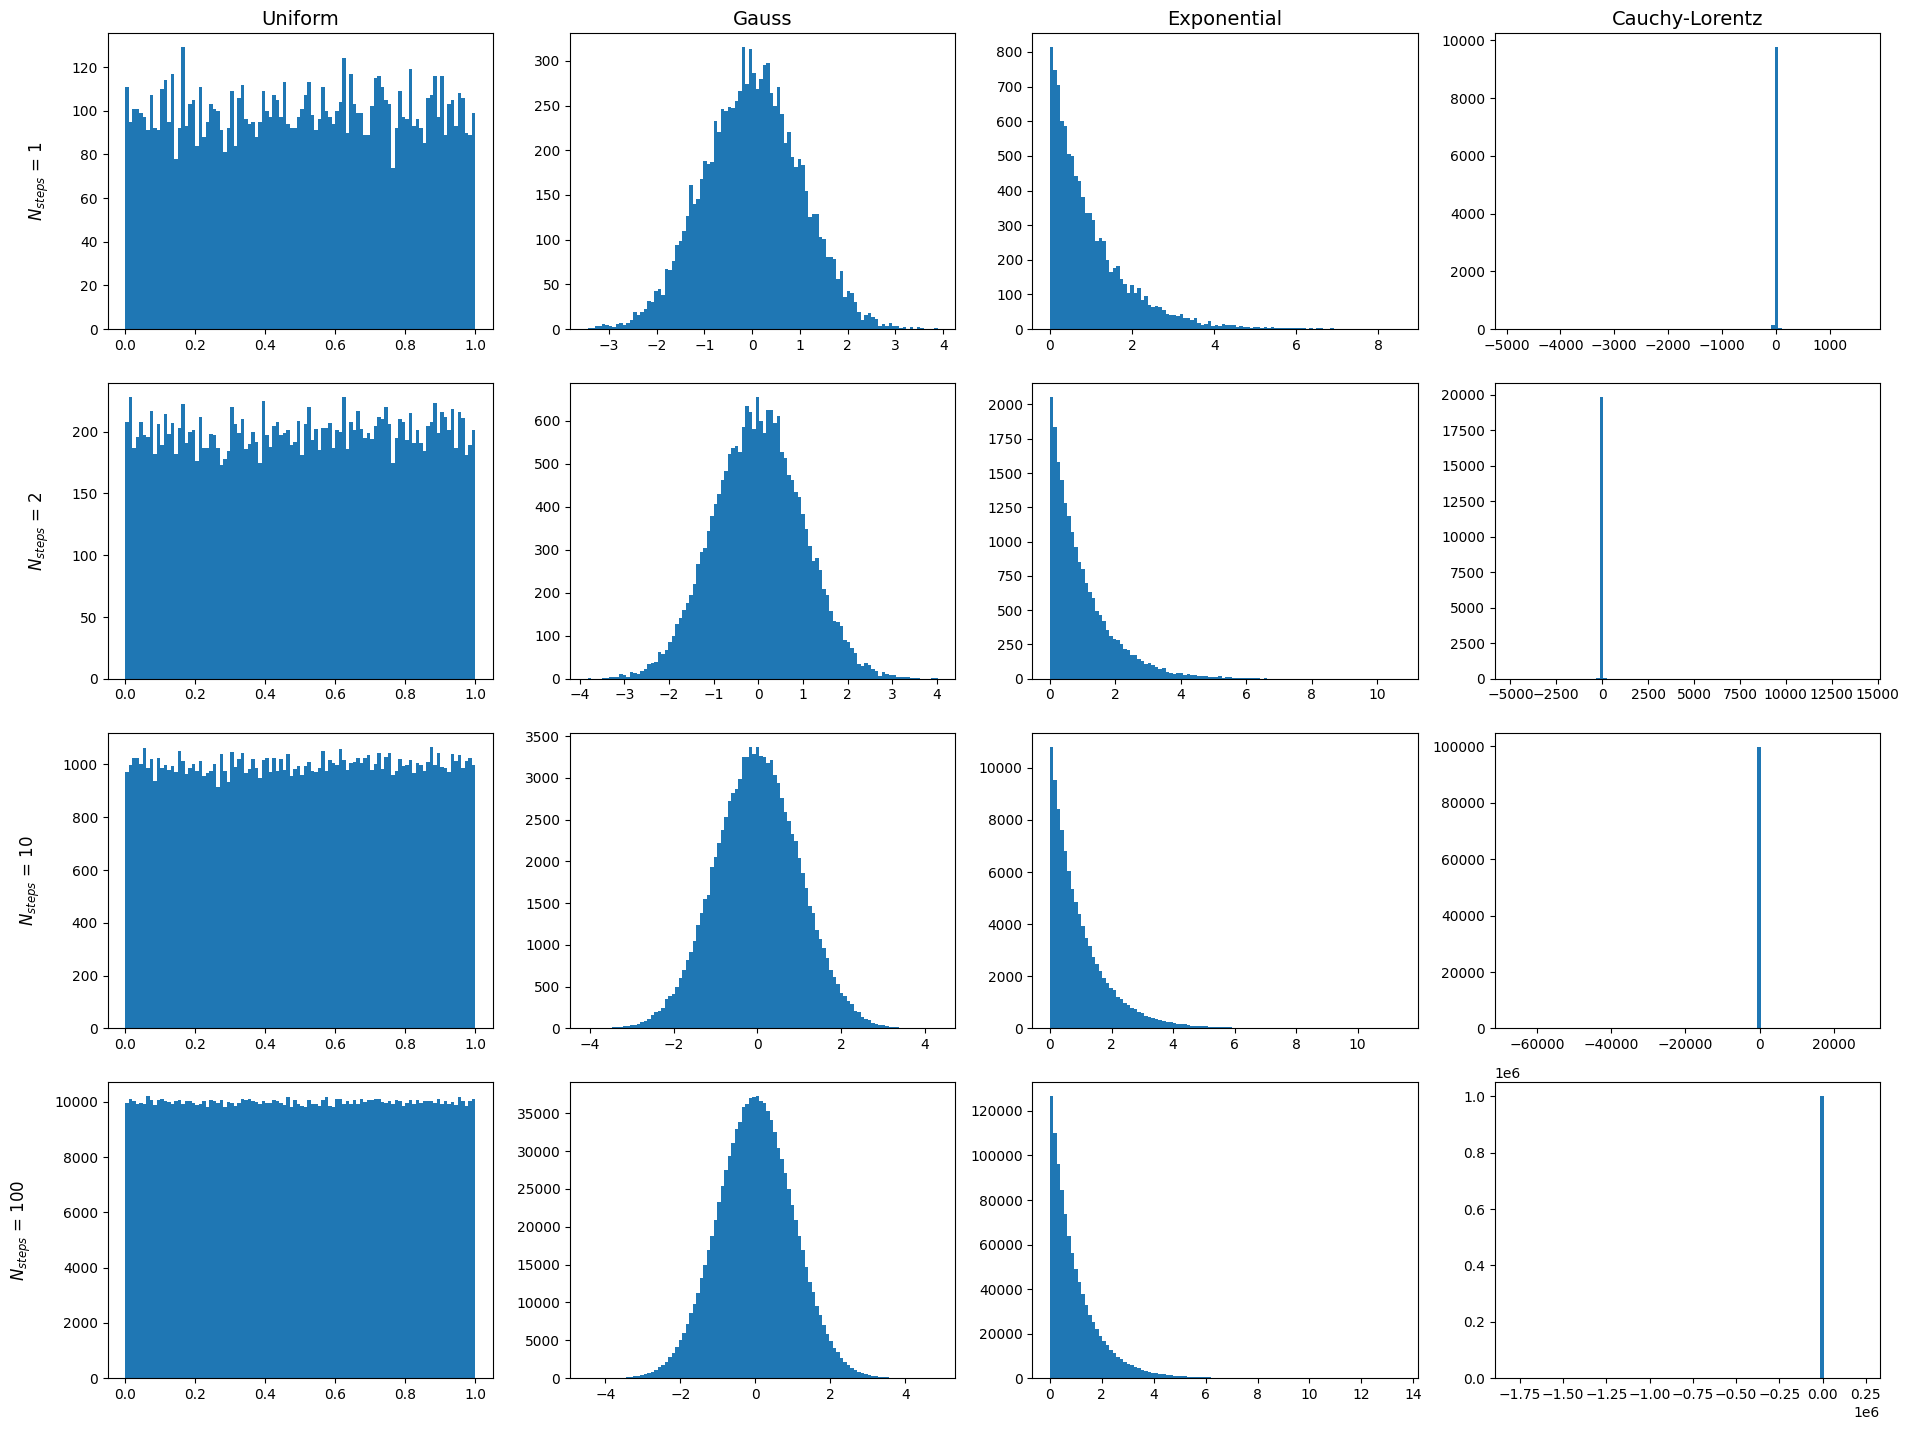

In [ ]:
N_blocks = int(1e4)
N_steps_range = np.array([1, 2, 10, 100])

fig, axs = plt.subplots(N_steps_range.size, 4)
fig.set_figwidth(19.2)
fig.set_figheight(14.4)

for i in range(N_steps_range.size):
  N_steps = N_steps_range[i]
  N_samples = N_blocks * N_steps

  output = subprocess.run(["./run", str(N_samples)], 
                        cwd="./rannyu_rng",
                        capture_output=True,
                        text=True)
  data_unif = np.fromstring(output.stdout, sep='\n')

  output = subprocess.run(["./run", str(N_samples), "gauss",  str(0.0),  str(1.0)], 
                        cwd="./rannyu_rng",
                        capture_output=True,
                        text=True)
  data_gauss = np.fromstring(output.stdout, sep='\n')

  output = subprocess.run(["./run", str(N_samples), "exp", str(1.0)], 
                        cwd="./rannyu_rng",
                        capture_output=True,
                        text=True)
  data_exp = np.fromstring(output.stdout, sep='\n')

  output = subprocess.run(["./run", str(N_samples), "lorentz", str(0.0), str(1.0)], 
                        cwd="./rannyu_rng",
                        capture_output=True,
                        text=True)
  data_lor = np.fromstring(output.stdout, sep='\n')

  axs[i][0].hist(data_unif, bins=100)
  axs[i][1].hist(data_gauss, bins=100)
  axs[i][2].hist(data_exp, bins=100)
  axs[i][3].hist(data_lor, bins=100)

col_labels = ["Uniform", "Gauss", "Exponential", "Cauchy-Lorentz"]
row_labels = [f"$N_{{steps}}$ = {n}" for n in N_steps_range]

for ax, col in zip(axs[0], col_labels):
    ax.set_title(col, fontsize=14)

for ax, row in zip(axs[:, 0], row_labels):
    ax.set_ylabel(row, fontsize=12, rotation=90, labelpad=15)

fig.tight_layout()

# Exercise 1.3: Buffon experiment simluation
> **Goal**: simulate throwing a stick of lenght $L$ across a series of parallel lines separated by a distance $d>L$. Then *measure* $\pi$ by counting the frequency with which the stick lands crossing a line.

A "Buffon mode" has been added to the random number generator, usable as
`./rannyu_rng/run <N_throws> "buffon" <L_value> <d_value>`
which returns the corresponding number of hits:

```cpp
int Random::buffon(int N_throws, double L, double d) {
  int hits = 0;

  for (int i = 0; i < N_throws; i++) {
    double x = rannyu(), y = rannyu();
    double r2 = x*x + y*y;
    while (r2 > 1) {
      x = rannyu();
      y = rannyu();
      r2 = x*x + y*y;
    }
    double sin_theta = std::abs(y) / std::sqrt(r2);
    double y_center = rannyu() * d/2;

    if (y_center <= sin_theta * L /2) {
      hits++;
    }
  }

  return hits;
}
```

then we can simulate a measure of $\pi$:

Final estimate of pi: 3.1417 +- 0.0031


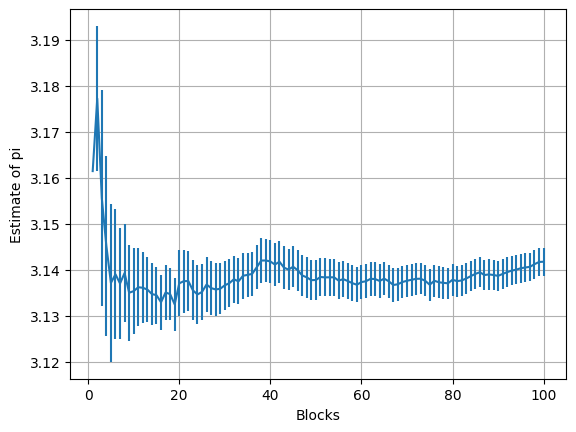

In [ ]:
d = 1.0
L = 0.8

N_blocks = 100
N_throws_per_block = int(1e4)

def buffon_hits(N, L, d, n):
  output = subprocess.run(["./run", str(N), "buffon", str(L), str(d), str(n)], 
                      cwd="./rannyu_rng",
                      capture_output=True,
                      text=True)
  hits_data = np.fromstring(output.stdout, sep='\n')
  return hits_data

hits_data = buffon_hits(N_blocks, L, d, N_throws_per_block)
av_blocks = np.zeros(N_blocks)
av2_blocks = np.zeros(N_blocks)
err_progr = np.zeros(N_blocks)
pi_est = np.zeros(N_blocks)

for block in range(N_blocks):
  pi_est[block] = 2 * L * N_throws_per_block / (d * hits_data[block])

  for i in range(N_blocks - block):
    av_blocks[block + i] += pi_est[block]
    av2_blocks[block + i] += pi_est[block]*pi_est[block]

for block in range(N_blocks):
  av_blocks[block] /= block + 1
  av2_blocks[block] /= block + 1
  err_progr[block] = math.sqrt( max((av2_blocks[block] - av_blocks[block]**2), 0) / max(block, 1) )

plt.errorbar(np.arange(1, N_blocks+1), av_blocks, yerr=err_progr)
plt.xlabel("Blocks")
plt.ylabel(f"Estimate of pi")
plt.grid(True)

print(f"Final estimate of pi: {av_blocks[N_blocks - 1]:.4f} +- {err_progr[N_blocks - 1]:.4f}")
